Hücre 1: Kütüphaneler

In [9]:

import time
import re
import warnings

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

import xgboost as xgb

from sklearn.model_selection import train_test_split, GridSearchCV
from sklearn.preprocessing import LabelEncoder, StandardScaler, label_binarize
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (accuracy_score,roc_auc_score, roc_curve, auc, confusion_matrix,classification_report)


warnings.filterwarnings('ignore')

%matplotlib inline

Hücre 2: Veri Yükleme ve Bazı Ön İşlemler

In [10]:
# Verimici yükleyelim
df = pd.read_csv('Credit_score_classification.csv')

#Gereksiz Sütunların Temizlenmesi
cols_to_drop = ['ID', 'Customer_ID', 'Name', 'SSN']
df = df.drop(columns=cols_to_drop, errors='ignore')


def clean_numeric_col(col_name):
    """İçinde alt çizgi (_) olan sayısal sütunları temizler."""
    if df[col_name].dtype == 'object':
        return pd.to_numeric(df[col_name].astype(str).str.replace('_', ''), errors='coerce')
    return df[col_name]

def parse_credit_history(val):
    """ '22 Years and 1 Months' formatını toplam aya çevirir."""
    if pd.isna(val): return np.nan
    val = str(val)
    if 'Years' in val and 'Months' in val:
        try:
            years = int(re.search(r'(\d+) Years', val).group(1))
            months = int(re.search(r'(\d+) Months', val).group(1))
            return years * 12 + months
        except:
            return np.nan
    return np.nan

# Temizleme işlemlerini uygula
numeric_candidates = ['Age', 'Annual_Income', 'Num_of_Loan', 'Num_of_Delayed_Payment', 
                      'Changed_Credit_Limit', 'Outstanding_Debt', 'Amount_invested_monthly', 
                      'Monthly_Balance']

for col in numeric_candidates:
    if col in df.columns:
        df[col] = clean_numeric_col(col)

if 'Credit_History_Age' in df.columns:
    df['Credit_History_Age'] = df['Credit_History_Age'].apply(parse_credit_history)

print("Temel temizlik tamamlandı. Veri boyutu:", df.shape)

Temel temizlik tamamlandı. Veri boyutu: (100000, 24)


Hücre 3: Aykırı Değer (Outlier) Analizi ve Temizliği

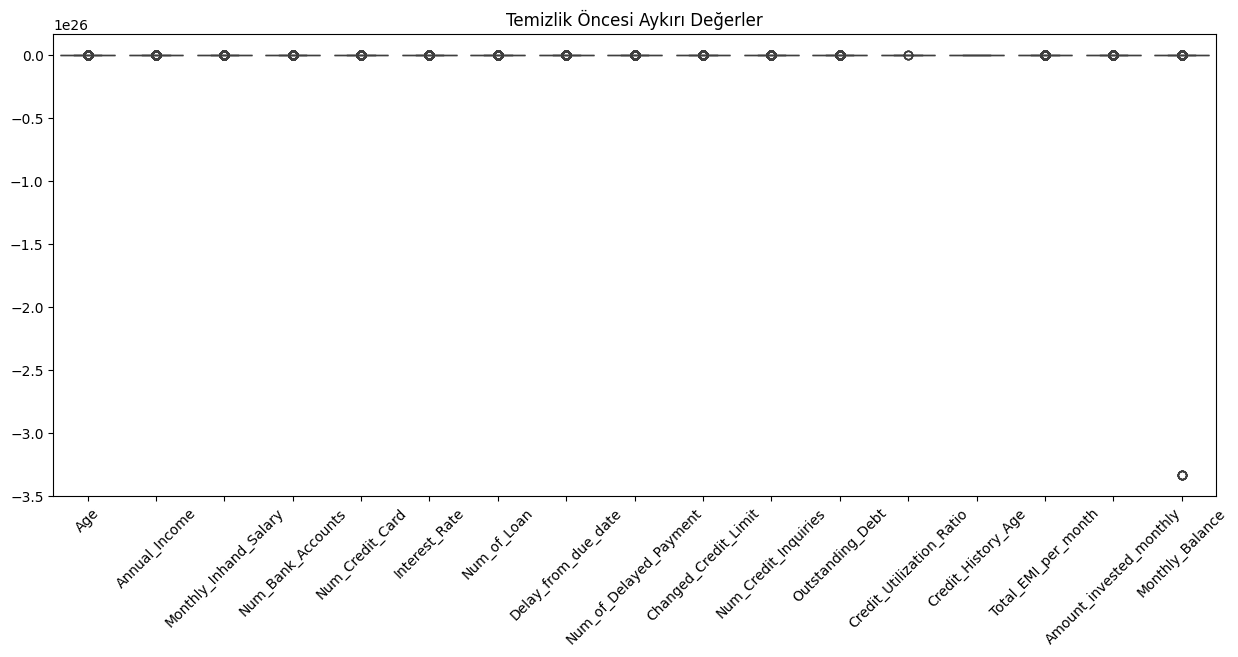

Aykırı değer temizliği yapıldı.


In [11]:
# Sadece sayısal sütunları seç
numeric_cols_detect = df.select_dtypes(include=[np.number]).columns

# Önce aykırı değerleri görelim (Boxplot)
plt.figure(figsize=(15, 6))
sns.boxplot(data=df[numeric_cols_detect[:]]) # İlk 10 sütun
plt.xticks(rotation=45)
plt.title("Temizlik Öncesi Aykırı Değerler")
plt.show()

# Aykırı değerleri baskılama (Capping) Fonksiyonu
def remove_outliers_iqr(df, columns):
    df_clean = df.copy()
    for col in columns:
        Q1 = df_clean[col].quantile(0.05) # Alt %5 
        Q3 = df_clean[col].quantile(0.95) # Üst %95
        IQR = Q3 - Q1
        
        lower_bound = Q1 - 1.5 * IQR
        upper_bound = Q3 + 1.5 * IQR
        
        # Değerleri alt ve üst sınıra eşitle
        df_clean[col] = df_clean[col].clip(lower=lower_bound, upper=upper_bound)
    return df_clean

# Target (Credit_Score) hariç temizle
cols_to_clean = [col for col in numeric_cols_detect if col != 'Credit_Score']
df = remove_outliers_iqr(df, cols_to_clean)

print("Aykırı değer temizliği yapıldı.")

Hücre 4: Veri Ön İşleme (Preprocessing)
Bu hücrede tanımladığımız fonksiyonları uyguluyor, eksik verileri dolduruyor ve kategorik verileri sayıya çeviriyoruz (Encoding).

In [12]:
# 1. Eksik verileri doldurma için katagorik ve sayısalları ayıralım
numeric_cols = df.select_dtypes(include=[np.number]).columns
categorical_cols = df.select_dtypes(exclude=[np.number]).columns

# Sayısal verilerde Medyan, Kategorik verilerde Mod kullanalım
imputer_num = SimpleImputer(strategy='median')
df[numeric_cols] = imputer_num.fit_transform(df[numeric_cols])

imputer_cat = SimpleImputer(strategy='most_frequent')
df[categorical_cols] = imputer_cat.fit_transform(df[categorical_cols])

# 2. Hedef Değişkeni (Credit_Score) Kodlama
score_mapping = {'Poor': 0, 'Standard': 1, 'Good': 2}
df = pd.DataFrame(df, columns=numeric_cols.append(categorical_cols))

if df['Credit_Score'].dtype == 'object':
    df['Credit_Score'] = df['Credit_Score'].map(score_mapping)

# NaN kalan target varsa temizle
df = df.dropna(subset=['Credit_Score'])

# 3. Diğer Kategorik Özellikleri Kodlama
le = LabelEncoder()
cat_cols = df.select_dtypes(include=['object']).columns 
for col in cat_cols:
    df[col] = le.fit_transform(df[col].astype(str))

print("Veri Ön İşleme Tamamlandı. Son Boyut:", df.shape)

Veri Ön İşleme Tamamlandı. Son Boyut: (100000, 24)


Hücre 5: Eğitim ve Test Seti Ayrımı (Train-Test Split)
Veriyi %80 Eğitim, %20 Test olarak ayırıyor ve ölçeklendirme yapıyoruz.

In [13]:
X = df.drop('Credit_Score', axis=1)
y = df['Credit_Score']

# %80 Train, %20 Test
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42, stratify=y)

# Standardizasyon
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

print(f"Train Seti: {X_train.shape}, Test Seti: {X_test.shape}")

Train Seti: (80000, 23), Test Seti: (20000, 23)


Hücre 6: Değerlendirme fonksiyonu model eğitimleri sonrası tekrar kullanmak için

In [14]:


def evaluate_model_performance(model_name, model, X_test, y_test, time_taken, 
                               best_params=None, result_dict=None, cm_cmap='Blues'):
    # Tahminler
    y_pred = model.predict(X_test)
    y_prob = model.predict_proba(X_test)
    
    # Metrik Hesaplama
    acc = accuracy_score(y_test, y_pred)
    try:
        roc_auc_val = roc_auc_score(y_test, y_prob, multi_class='ovr', average='weighted')
    except:
        roc_auc_val = 0
        
    # Başlık ve Parametre Gösterimi
    is_opt = best_params is not None
    title_prefix = "OPTIMIZED " if is_opt else ""
    
    print(f"\n{'='*70}")
    print(f"{title_prefix}MODEL RAPORU: {model_name.upper()}")
    print(f"{'='*70}")
    
    if is_opt:
        print(f"┌{'─'*30}┐")
        print(f"│ {'En İyi Parametreler':^30} │")
        print(f"└{'─'*30}┘")
        for param, value in best_params.items():
            print(f" • {param:<20} : {value}")
        print("")

    # Sayısal Özet Tablo
    print(f"┌{'─'*25}┬{'─'*15}┐")
    print(f"│ {'Metrik':<23} │ {'Değer':<13} │")
    print(f"├{'─'*25}┼{'─'*15}┤")
    print(f"│ {'İşlem Süresi (sn)':<23} │ {time_taken:<13.4f} │")
    print(f"│ {'Accuracy':<23} │ {acc:<13.4f} │")
    print(f"│ {'ROC-AUC':<23} │ {roc_auc_val:<13.4f} │")
    print(f"└{'─'*25}┴{'─'*15}┘\n")
    
    print("--- Sınıflandırma Detayları ---")
    print(classification_report(y_test, y_pred, digits=4))

    # Görselleştirme
    fig, ax = plt.subplots(1, 2, figsize=(14, 5))

    # Confusion Matrix
    cm = confusion_matrix(y_test, y_pred)
    sns.heatmap(cm, annot=True, fmt='d', cmap=cm_cmap, ax=ax[0],
                xticklabels=['Poor', 'Standard', 'Good'], 
                yticklabels=['Poor', 'Standard', 'Good'])
    ax[0].set_title(f'Confusion Matrix - {model_name}')
    ax[0].set_ylabel('Gerçek')
    ax[0].set_xlabel('Tahmin')

    # ROC Curve
    y_test_bin = label_binarize(y_test, classes=[0, 1, 2])
    n_classes = y_test_bin.shape[1]
    classes = ['Poor', 'Standard', 'Good']
    colors = ['red', 'blue', 'green']
    
    for i, color in zip(range(n_classes), colors):
        fpr, tpr, _ = roc_curve(y_test_bin[:, i], y_prob[:, i])
        area = auc(fpr, tpr)
        ax[1].plot(fpr, tpr, color=color, lw=2, label=f'{classes[i]} (AUC={area:.2f})')
    
    ax[1].plot([0, 1], [0, 1], 'k--', lw=2)
    ax[1].set_title(f'ROC Curve - {model_name}')
    ax[1].legend(loc="lower right")
    plt.tight_layout()
    plt.show()

    # Sonuçları Kaydetme 
    if result_dict is not None:
        result_dict[model_name] = {
            'Süre (sn)': time_taken,
            'Accuracy': acc,
            'ROC-AUC': roc_auc_val,
            'Parametreler': str(best_params) if is_opt else "Varsayılan"
        }

Hücre 7: 3 Farklı Modelin Eğitimi


>>> 1. Logistic Regression...

MODEL RAPORU: LOGISTIC REGRESSION
┌─────────────────────────┬───────────────┐
│ Metrik                  │ Değer         │
├─────────────────────────┼───────────────┤
│ İşlem Süresi (sn)       │ 0.1802        │
│ Accuracy                │ 0.6191        │
│ ROC-AUC                 │ 0.7535        │
└─────────────────────────┴───────────────┘

--- Sınıflandırma Detayları ---
              precision    recall  f1-score   support

           0     0.6386    0.4659    0.5388      5799
           1     0.6247    0.7758    0.6921     10635
           2     0.5584    0.4010    0.4668      3566

    accuracy                         0.6191     20000
   macro avg     0.6072    0.5476    0.5659     20000
weighted avg     0.6169    0.6191    0.6075     20000



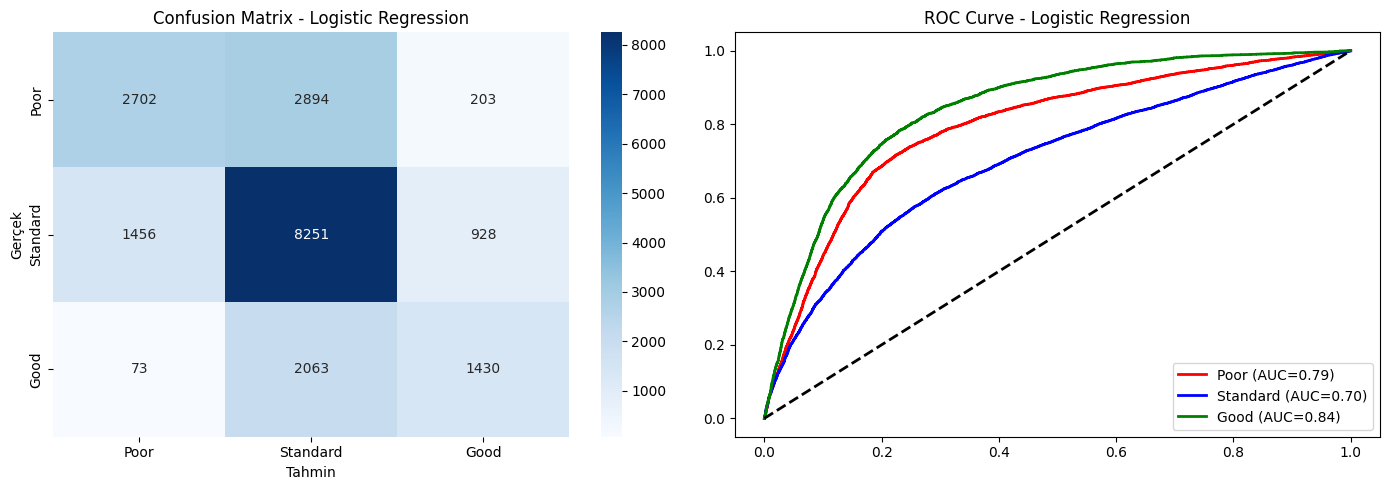


>>> 2. Random Forest...

MODEL RAPORU: RANDOM FOREST
┌─────────────────────────┬───────────────┐
│ Metrik                  │ Değer         │
├─────────────────────────┼───────────────┤
│ İşlem Süresi (sn)       │ 22.0836       │
│ Accuracy                │ 0.7883        │
│ ROC-AUC                 │ 0.8939        │
└─────────────────────────┴───────────────┘

--- Sınıflandırma Detayları ---
              precision    recall  f1-score   support

           0     0.7861    0.8017    0.7938      5799
           1     0.8072    0.8090    0.8081     10635
           2     0.7333    0.7047    0.7187      3566

    accuracy                         0.7883     20000
   macro avg     0.7755    0.7718    0.7736     20000
weighted avg     0.7879    0.7883    0.7880     20000



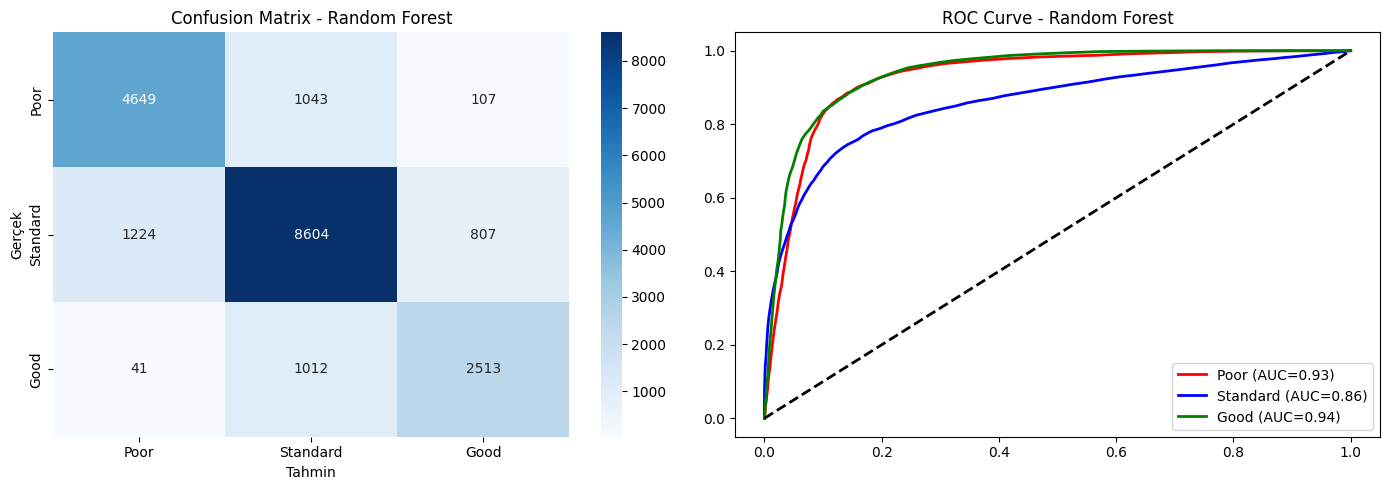


>>> 3. XGBoost...

MODEL RAPORU: XGBOOST
┌─────────────────────────┬───────────────┐
│ Metrik                  │ Değer         │
├─────────────────────────┼───────────────┤
│ İşlem Süresi (sn)       │ 1.0251        │
│ Accuracy                │ 0.7591        │
│ ROC-AUC                 │ 0.8819        │
└─────────────────────────┴───────────────┘

--- Sınıflandırma Detayları ---
              precision    recall  f1-score   support

           0     0.7623    0.7401    0.7511      5799
           1     0.7820    0.7913    0.7866     10635
           2     0.6861    0.6943    0.6902      3566

    accuracy                         0.7591     20000
   macro avg     0.7435    0.7419    0.7426     20000
weighted avg     0.7592    0.7591    0.7591     20000



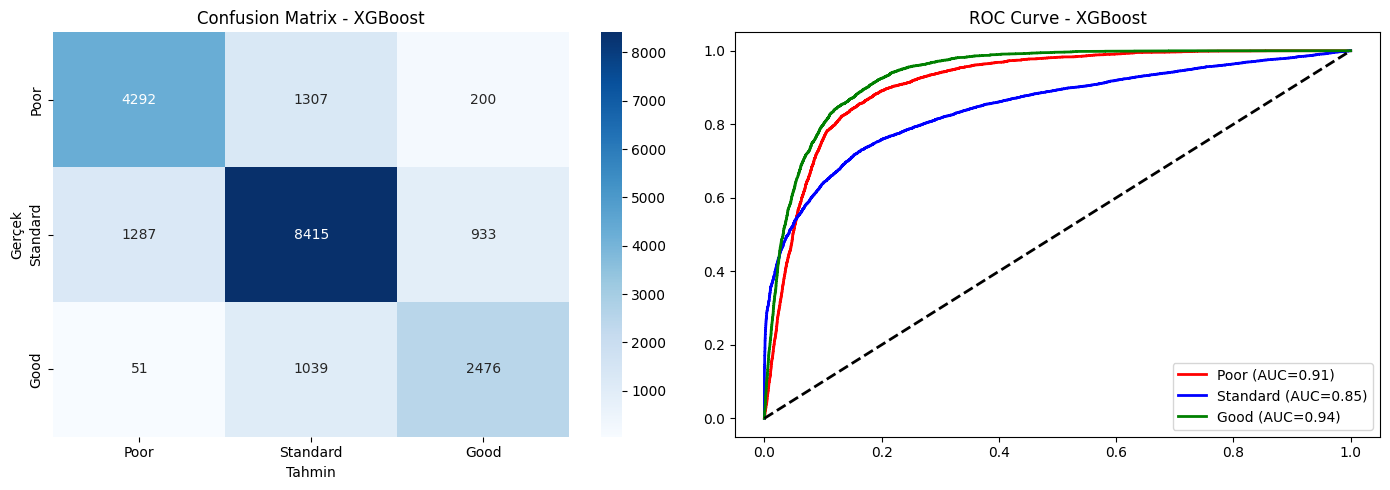


=== TEMEL MODEL SONUÇLARI ===
                     Süre (sn) Accuracy   ROC-AUC Parametreler
Random Forest        22.083585   0.7883  0.893887   Varsayılan
XGBoost               1.025116  0.75915  0.881947   Varsayılan
Logistic Regression   0.180152  0.61915  0.753511   Varsayılan


In [15]:

# Sonuçları tutacak sözlük
base_results = {}

# Logistic Regression
print("\n>>> 1. Logistic Regression...")
start = time.time()
lr = LogisticRegression(max_iter=1000, random_state=42)
lr.fit(X_train_scaled, y_train)
lr_time = time.time() - start

evaluate_model_performance("Logistic Regression", lr, X_test_scaled, y_test, lr_time, 
                           result_dict=base_results, cm_cmap='Blues')

# Random Forest
print("\n>>> 2. Random Forest...")
start = time.time()
rf = RandomForestClassifier(n_estimators=100, random_state=42)
rf.fit(X_train, y_train)
rf_time = time.time() - start
evaluate_model_performance("Random Forest", rf, X_test, y_test, rf_time, 
                           result_dict=base_results, cm_cmap='Blues')

# XGBoost
print("\n>>> 3. XGBoost...")
start = time.time()
xgb_clf = xgb.XGBClassifier(use_label_encoder=False, eval_metric='mlogloss', random_state=42)
xgb_clf.fit(X_train, y_train)
xgb_time = time.time() - start
evaluate_model_performance("XGBoost", xgb_clf, X_test, y_test, xgb_time, 
                           result_dict=base_results, cm_cmap='Blues')

# Tablo
print("\n=== TEMEL MODEL SONUÇLARI ===")
print(pd.DataFrame(base_results).T.sort_values(by='Accuracy', ascending=False))

Hücre 8: Hiperparametre Optimizasyonu

>>> 1. Random Forest GridSearch Başlatılıyor...
Fitting 3 folds for each of 4 candidates, totalling 12 fits

OPTIMIZED MODEL RAPORU: RANDOM FOREST (OPT)
┌──────────────────────────────┐
│      En İyi Parametreler       │
└──────────────────────────────┘
 • max_depth            : None
 • n_estimators         : 100

┌─────────────────────────┬───────────────┐
│ Metrik                  │ Değer         │
├─────────────────────────┼───────────────┤
│ İşlem Süresi (sn)       │ 46.8325       │
│ Accuracy                │ 0.7883        │
│ ROC-AUC                 │ 0.8939        │
└─────────────────────────┴───────────────┘

--- Sınıflandırma Detayları ---
              precision    recall  f1-score   support

           0     0.7861    0.8017    0.7938      5799
           1     0.8072    0.8090    0.8081     10635
           2     0.7333    0.7047    0.7187      3566

    accuracy                         0.7883     20000
   macro avg     0.7755    0.7718    0.7736     20000
weighted avg     

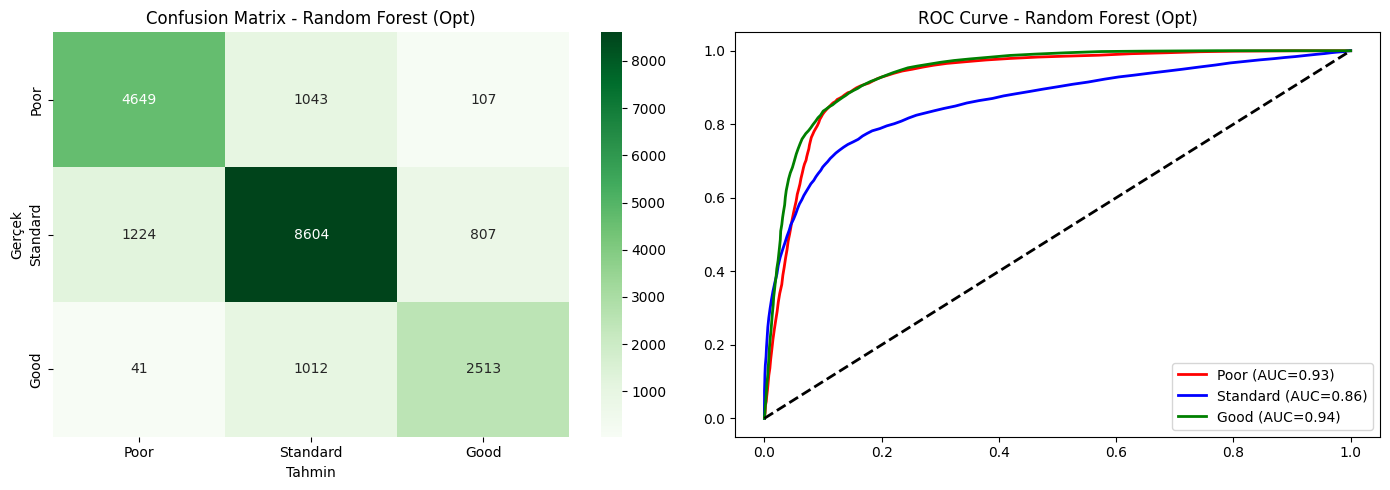


>>> 2. XGBoost GridSearch Başlatılıyor...
Fitting 3 folds for each of 4 candidates, totalling 12 fits

OPTIMIZED MODEL RAPORU: XGBOOST (OPT)
┌──────────────────────────────┐
│      En İyi Parametreler       │
└──────────────────────────────┘
 • learning_rate        : 0.2
 • max_depth            : 6

┌─────────────────────────┬───────────────┐
│ Metrik                  │ Değer         │
├─────────────────────────┼───────────────┤
│ İşlem Süresi (sn)       │ 8.5851        │
│ Accuracy                │ 0.7470        │
│ ROC-AUC                 │ 0.8748        │
└─────────────────────────┴───────────────┘

--- Sınıflandırma Detayları ---
              precision    recall  f1-score   support

           0     0.7571    0.7155    0.7357      5799
           1     0.7719    0.7844    0.7781     10635
           2     0.6593    0.6865    0.6726      3566

    accuracy                         0.7470     20000
   macro avg     0.7294    0.7288    0.7288     20000
weighted avg     0.7475    0.74

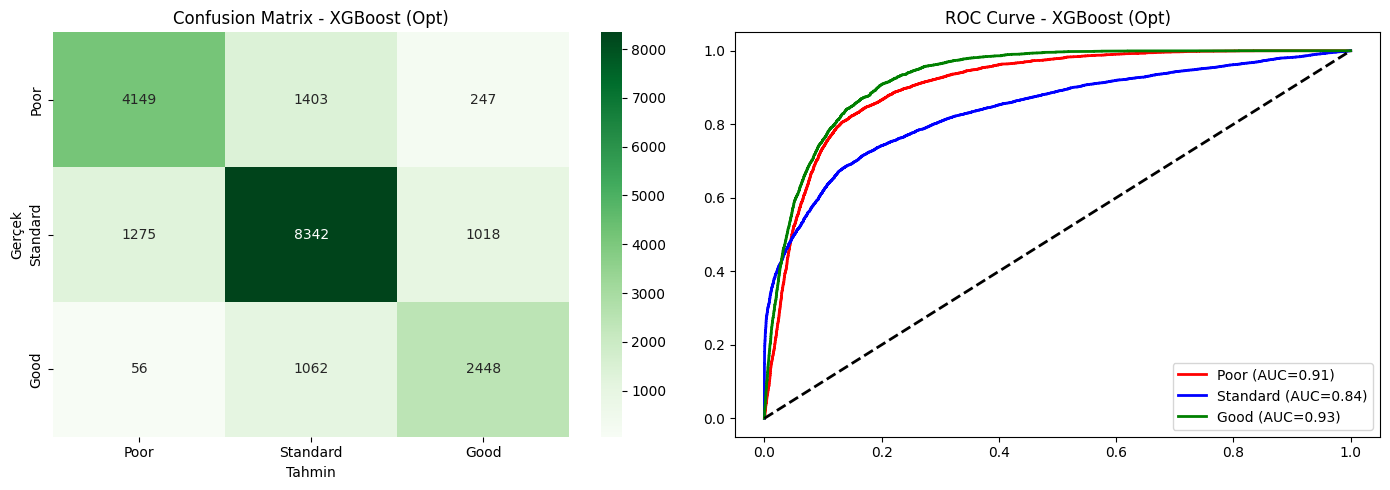


>>> 3. Logistic Regression GridSearch Başlatılıyor...
Fitting 3 folds for each of 3 candidates, totalling 9 fits

OPTIMIZED MODEL RAPORU: LOGISTIC REG (OPT)
┌──────────────────────────────┐
│      En İyi Parametreler       │
└──────────────────────────────┘
 • C                    : 0.1
 • solver               : lbfgs

┌─────────────────────────┬───────────────┐
│ Metrik                  │ Değer         │
├─────────────────────────┼───────────────┤
│ İşlem Süresi (sn)       │ 0.7395        │
│ Accuracy                │ 0.6192        │
│ ROC-AUC                 │ 0.7535        │
└─────────────────────────┴───────────────┘

--- Sınıflandırma Detayları ---
              precision    recall  f1-score   support

           0     0.6388    0.4659    0.5388      5799
           1     0.6246    0.7759    0.6921     10635
           2     0.5588    0.4010    0.4669      3566

    accuracy                         0.6192     20000
   macro avg     0.6074    0.5476    0.5660     20000
weighted av

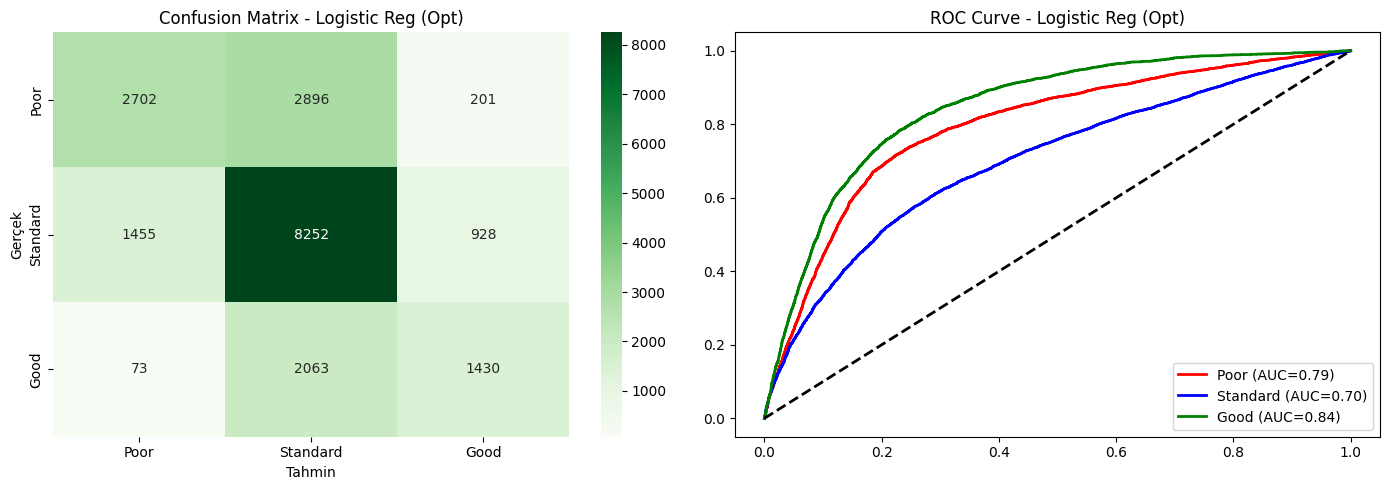


=== TÜM OPTİMİZE MODELLERİN SONUÇLARI ===
                     Süre (sn) Accuracy   ROC-AUC  \
Random Forest (Opt)  46.832541   0.7883  0.893887   
XGBoost (Opt)         8.585126  0.74695  0.874762   
Logistic Reg (Opt)    0.739479   0.6192  0.753508   

                                                 Parametreler  
Random Forest (Opt)  {'max_depth': None, 'n_estimators': 100}  
XGBoost (Opt)          {'learning_rate': 0.2, 'max_depth': 6}  
Logistic Reg (Opt)              {'C': 0.1, 'solver': 'lbfgs'}  


In [16]:


# Sonuçları tutacak sözlük 
opt_results = {}

# RANDOM FOREST OPTIMIZASYON
print(">>> 1. Random Forest GridSearch Başlatılıyor...")
start = time.time()
# Parametreleri hızlı bitsin diye az tuttum, sen artırabilirsin
grid_rf = GridSearchCV(RandomForestClassifier(random_state=42), 
                       {'n_estimators': [50, 100], 'max_depth': [10, None]}, 
                       cv=3, verbose=1, n_jobs=-1)
grid_rf.fit(X_train, y_train)
rf_opt_time = time.time() - start

evaluate_model_performance("Random Forest (Opt)", grid_rf.best_estimator_, X_test, y_test, rf_opt_time,
                           best_params=grid_rf.best_params_, 
                           result_dict=opt_results, cm_cmap='Greens')

# XGBOOST OPTIMIZASYON
print("\n>>> 2. XGBoost GridSearch Başlatılıyor...")
start = time.time()
grid_xgb = GridSearchCV(xgb.XGBClassifier(use_label_encoder=False, eval_metric='mlogloss', random_state=42), 
                        {'learning_rate': [0.1, 0.2], 'max_depth': [3, 6]}, 
                        cv=3, verbose=1, n_jobs=-1)
grid_xgb.fit(X_train, y_train)
xgb_opt_time = time.time() - start

evaluate_model_performance("XGBoost (Opt)", grid_xgb.best_estimator_, X_test, y_test, xgb_opt_time,
                           best_params=grid_xgb.best_params_, 
                           result_dict=opt_results, cm_cmap='Greens')


# LOGISTIC REGRESSION OPTIMIZASYON
print("\n>>> 3. Logistic Regression GridSearch Başlatılıyor...")
start = time.time()
grid_lr = GridSearchCV(LogisticRegression(random_state=42), 
                       {'C': [0.1, 1, 10], 'solver': ['lbfgs']}, 
                       cv=3, verbose=1, n_jobs=-1)
grid_lr.fit(X_train_scaled, y_train)
lr_opt_time = time.time() - start

evaluate_model_performance("Logistic Reg (Opt)", grid_lr.best_estimator_, X_test_scaled, y_test, lr_opt_time,
                           best_params=grid_lr.best_params_, 
                           result_dict=opt_results, cm_cmap='Greens')


# SONUÇ TABLOSU
print("\n=== TÜM OPTİMİZE MODELLERİN SONUÇLARI ===")
print(pd.DataFrame(opt_results).T.sort_values(by='Accuracy', ascending=False))


Hücre 9: Özellik Önemi (Feature Importance)


==================== Random Forest ÖZELLİK ÖNEMİ KIYASLAMASI ====================


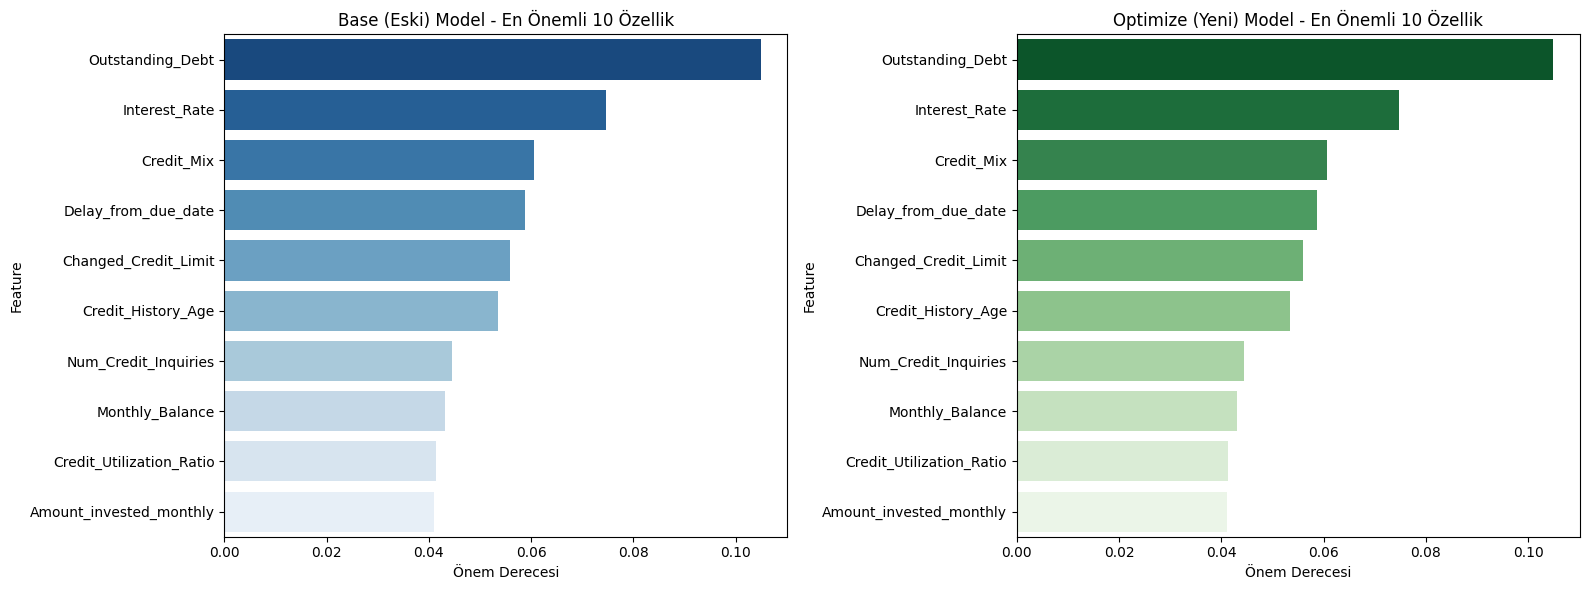


==================== XGBoost ÖZELLİK ÖNEMİ KIYASLAMASI ====================


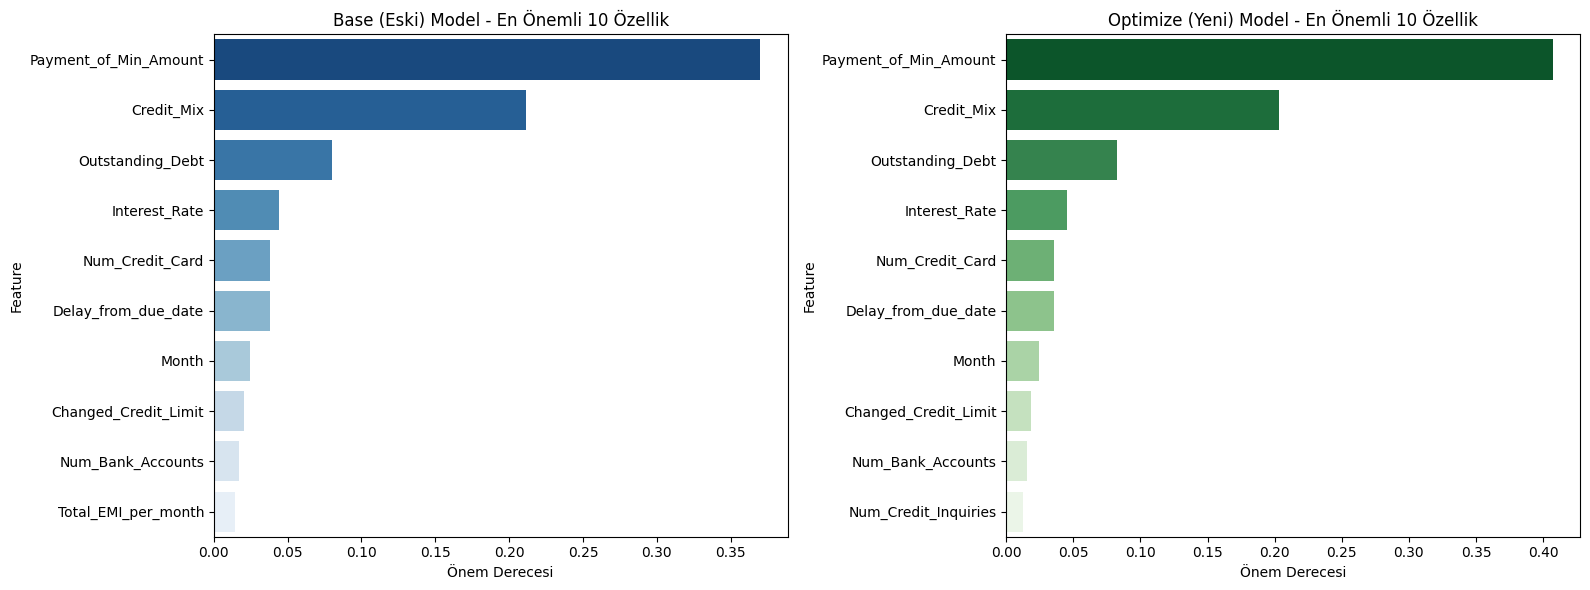


==================== Logistic Regression ÖZELLİK ÖNEMİ KIYASLAMASI ====================


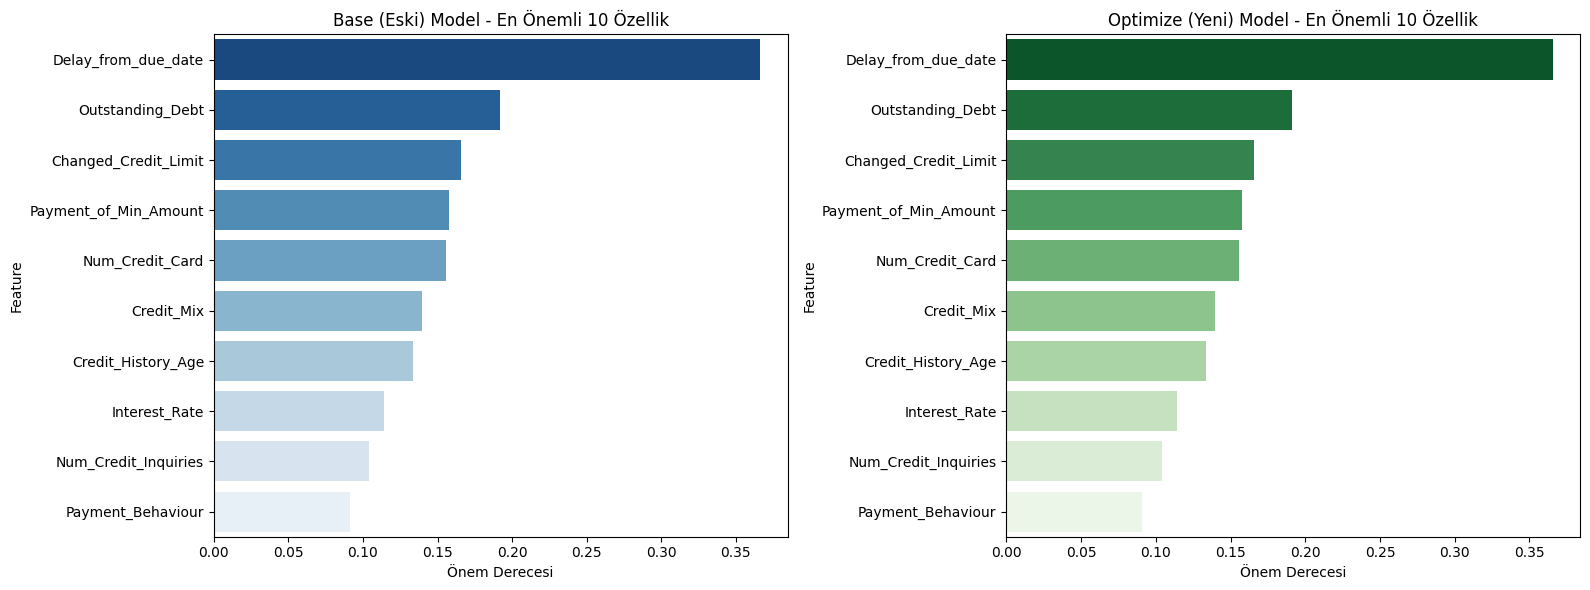

In [17]:


# --- KIYASLAMALI ÖZELLİK ÖNEMİ ANALİZİ FONKSİYONU ---
def plot_importance_comparison(model_name, base_model, opt_model, X_columns):
    """
    Base ve Optimize modellerin özellik önemlerini yan yana çizer.
    """
    print(f"\n{'='*20} {model_name} ÖZELLİK ÖNEMİ KIYASLAMASI {'='*20}")
    
    fig, axes = plt.subplots(1, 2, figsize=(16, 6))
    
    # Modelleri ve Başlıkları Listele
    models = [(base_model, "Base (Eski) Model", axes[0], 'Blues_r'), 
              (opt_model, "Optimize (Yeni) Model", axes[1], 'Greens_r')]
    
    for model, title, ax, palette in models:
        importances = None
        
        #Ağaç Tabanlı
        if hasattr(model, 'feature_importances_'):
            importances = model.feature_importances_
            
        #Lineer - Logistic Reg.
        elif hasattr(model, 'coef_'):
            importances = np.mean(np.abs(model.coef_), axis=0)
            
        if importances is not None:
            # DataFrame oluştur
            feat_df = pd.DataFrame({
                'Feature': X_columns,
                'Importance': importances
            }).sort_values(by='Importance', ascending=False).head(10) # İlk 10 özellik
            
            # Grafik Çiz
            sns.barplot(x='Importance', y='Feature', data=feat_df, ax=ax, palette=palette)
            ax.set_title(f'{title} - En Önemli 10 Özellik')
            ax.set_xlabel('Önem Derecesi')
        else:
            ax.text(0.5, 0.5, "Özellik Önemi Hesaplanamadı", ha='center')

    plt.tight_layout()
    plt.show()

# MODELLERİ KONTROL ET VE ÇİZ
feature_names = X.columns if 'X' in locals() else df.drop('Credit_Score', axis=1).columns

# Random Forest Kıyaslama
if 'rf' in locals() and 'grid_rf' in locals():
    plot_importance_comparison("Random Forest", rf, grid_rf.best_estimator_, feature_names)

# XGBoost Kıyaslama
if 'xgb_clf' in locals() and 'grid_xgb' in locals():
    plot_importance_comparison("XGBoost", xgb_clf, grid_xgb.best_estimator_, feature_names)

# Logistic Regression Kıyaslama
if 'lr' in locals() and 'grid_lr' in locals():
    plot_importance_comparison("Logistic Regression", lr, grid_lr.best_estimator_, feature_names)